In [1]:

# ============================================================
# CELL 1 — Imports and global settings
# ============================================================

from pathlib import Path
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:
from pathlib import Path
import os

# Detect repository root
REPO_ROOT = Path(
    os.environ.get("FORCE_REPO_ROOT", Path.cwd())
).expanduser().resolve()

if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

if not (REPO_ROOT / "notebooks").is_dir():
    raise FileNotFoundError(
        "Repository root not found. "
        "Start Jupyter from the repository root or notebooks folder, "
        "or set FORCE_REPO_ROOT."
    )

# Raw dataset directory
DATA_DIR = Path(
    os.environ.get(
        "FORCE_DATA_DIR",
        REPO_ROOT / "data" / "raw"
    )
).expanduser().resolve()

# Output directory
RESULTS_ROOT = Path(
    os.environ.get(
        "FORCE_RESULTS_DIR",
        REPO_ROOT / "outputs"
    )
).expanduser().resolve()

RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_ROOT)
print("Data:", DATA_DIR)
print("Outputs:", RESULTS_ROOT)

In [ ]:

# ============================================================
# CELL 2 — File paths
# ============================================================

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

OUTPUT_DIR = RESULTS_ROOT / "00_dataset_audit"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Train path :", TRAIN_PATH)
print("Test path  :", TEST_PATH)
print("Output dir :", OUTPUT_DIR)

def check_file(path: Path, label: str) -> None:
    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"✅ {label} exists — {size_mb:,.2f} MB")
    else:
        print(f"❌ {label} was not found: {path}")
        desktop = path.parent
        if desktop.exists():
            csv_files = sorted(desktop.glob("*.csv"))
            print(f"\nCSV files currently found in {desktop}:")
            for f in csv_files:
                print("  -", f.name)

check_file(TRAIN_PATH, "TRAIN")
check_file(TEST_PATH, "TEST")

assert TRAIN_PATH.exists(), f"Train file not found: {TRAIN_PATH}"
assert TEST_PATH.exists(), f"Test file not found: {TEST_PATH}"


Train path : /Users/mohaddesemoghaddam/Desktop/train.csv
Test path  : /Users/mohaddesemoghaddam/Desktop/test.csv
Output dir : /Users/mohaddesemoghaddam/Desktop/force2020_dataset_audit
✅ TRAIN exists — 267.49 MB
✅ TEST exists — 29.01 MB


In [3]:

# ============================================================
# CELL 3 — Column names and official lithology mapping
# ============================================================

WELL_COL = "WELL"
DEPTH_COL = "DEPTH_MD"
TARGET_COL = "FORCE_2020_LITHOFACIES_LITHOLOGY"
CONFIDENCE_COL = "FORCE_2020_LITHOFACIES_CONFIDENCE"

LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65030: "Sandstone/Shale",
    65000: "Shale",
    80000: "Marl",
    74000: "Dolomite",
    70000: "Limestone",
    70032: "Chalk",
    88000: "Halite",
    86000: "Anhydrite",
    99000: "Tuff",
    90000: "Coal",
    93000: "Basement",
}

EXPECTED_LITHOLOGY_CODES = set(LITHOLOGY_NAMES)
EXPECTED_TRAIN_WELLS = 98
EXPECTED_TEST_WELLS = 10

print("Expected lithology classes:", len(EXPECTED_LITHOLOGY_CODES))
display(
    pd.DataFrame(
        sorted(LITHOLOGY_NAMES.items()),
        columns=["Lithology_Code", "Lithology_Name"]
    )
)


Expected lithology classes: 12


,Lithology_Code,Lithology_Name
0,30000,Sandstone
1,65000,Shale
2,65030,Sandstone/Shale
3,70000,Limestone
4,70032,Chalk
5,74000,Dolomite
6,80000,Marl
7,86000,Anhydrite
8,88000,Halite
9,90000,Coal


In [4]:

# ============================================================
# CELL 4 — Safe CSV loading functions
# ============================================================

def detect_csv_format(file_path: Path, num_lines: int = 5) -> dict:
    encodings = ["utf-8", "latin1", "iso-8859-1", "cp1252"]

    for encoding in encodings:
        try:
            with open(file_path, "r", encoding=encoding) as f:
                lines = [f.readline() for _ in range(num_lines)]

            text = "".join(lines)
            candidates = {
                ",": text.count(","),
                ";": text.count(";"),
                "\t": text.count("\t"),
            }
            delimiter = max(candidates, key=candidates.get)

            return {"encoding": encoding, "sep": delimiter}
        except UnicodeDecodeError:
            continue

    return {"encoding": "utf-8", "sep": ","}


def load_csv_in_chunks(
    file_path: Path,
    chunk_size: int = 200_000,
) -> pd.DataFrame:
    csv_format = detect_csv_format(file_path)

    print(f"\nLoading: {file_path}")
    print("Detected format:", csv_format)

    chunks = []
    total_rows = 0

    reader = pd.read_csv(
        file_path,
        sep=csv_format["sep"],
        encoding=csv_format["encoding"],
        chunksize=chunk_size,
        low_memory=False,
    )

    for chunk_number, chunk in enumerate(reader, start=1):
        chunks.append(chunk)
        total_rows += len(chunk)
        print(
            f"  Chunk {chunk_number:02d}: "
            f"{len(chunk):,} rows | cumulative={total_rows:,}"
        )

    if not chunks:
        raise ValueError(f"No rows were loaded from {file_path}")

    df = pd.concat(chunks, ignore_index=True)
    print(f"✅ Loaded shape: {df.shape}")
    return df


In [ ]:

# ============================================================
# CELL 5 — Load raw datasets
# این سلول فقط داده خام را می‌خواند
# ============================================================

train_raw = load_csv_in_chunks(TRAIN_PATH)
test_raw = load_csv_in_chunks(TEST_PATH)


train_df = train_raw.copy()
test_df = test_raw.copy()

print("\nFinal loaded datasets:")
print("train_df:", train_df.shape)
print("test_df :", test_df.shape)



Loading: /Users/mohaddesemoghaddam/Desktop/train.csv
Detected format: {'encoding': 'utf-8', 'sep': ','}
  Chunk 01: 200,000 rows | cumulative=200,000
  Chunk 02: 200,000 rows | cumulative=400,000
  Chunk 03: 200,000 rows | cumulative=600,000
  Chunk 04: 200,000 rows | cumulative=800,000
  Chunk 05: 200,000 rows | cumulative=1,000,000
  Chunk 06: 170,511 rows | cumulative=1,170,511
✅ Loaded shape: (1170511, 29)

Loading: /Users/mohaddesemoghaddam/Desktop/test.csv
Detected format: {'encoding': 'utf-8', 'sep': ','}
  Chunk 01: 122,397 rows | cumulative=122,397
✅ Loaded shape: (122397, 29)

Final loaded datasets:
train_df: (1170511, 29)
test_df : (122397, 29)


In [6]:

# ============================================================
# CELL 6 — Basic dataset overview
# ============================================================

def dataset_overview(df: pd.DataFrame, dataset_name: str) -> dict:
    has_well = WELL_COL in df.columns
    has_depth = DEPTH_COL in df.columns
    has_target = TARGET_COL in df.columns

    return {
        "Dataset": dataset_name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Unique_Wells": df[WELL_COL].nunique(dropna=True) if has_well else np.nan,
        "Has_Depth": has_depth,
        "Has_Target": has_target,
        "Unique_Targets": df[TARGET_COL].nunique(dropna=True) if has_target else np.nan,
        "Duplicate_Rows": int(df.duplicated().sum()),
        "Memory_MB": df.memory_usage(deep=True).sum() / (1024 ** 2),
    }

overview = pd.DataFrame([
    dataset_overview(train_df, "Train"),
    dataset_overview(test_df, "Test"),
])

display(
    overview.style.format({
        "Rows": "{:,.0f}",
        "Columns": "{:,.0f}",
        "Unique_Wells": "{:,.0f}",
        "Unique_Targets": "{:,.0f}",
        "Duplicate_Rows": "{:,.0f}",
        "Memory_MB": "{:,.2f}",
    })
)

assert WELL_COL in train_df.columns, f"{WELL_COL} is missing from Train."
assert WELL_COL in test_df.columns, f"{WELL_COL} is missing from Test."
assert TARGET_COL in train_df.columns, f"{TARGET_COL} is missing from Train."

train_well_count = train_df[WELL_COL].nunique(dropna=True)
test_well_count = test_df[WELL_COL].nunique(dropna=True)

if train_well_count != EXPECTED_TRAIN_WELLS:
    print(
        f"⚠️ Train contains {train_well_count} wells, "
        f"while the expected FORCE training count is {EXPECTED_TRAIN_WELLS}."
    )
else:
    print("✅ Train contains 98 unique wells.")

if test_well_count != EXPECTED_TEST_WELLS:
    print(
        f"⚠️ Test contains {test_well_count} wells, "
        f"while the expected test count is {EXPECTED_TEST_WELLS}."
    )
else:
    print("✅ Test contains 10 unique wells.")


,Dataset,Rows,Columns,Unique_Wells,Has_Depth,Has_Target,Unique_Targets,Duplicate_Rows,Memory_MB
0,Train,"1,170,511",29,98,True,True,12,0,450.87
1,Test,"122,397",29,10,True,True,11,0,47.39


✅ Train contains 98 unique wells.
✅ Test contains 10 unique wells.


In [7]:

# ============================================================
# CELL 7 — First rows, last rows, columns and data types
# ============================================================

print("TRAIN — first 5 rows")
display(train_df.head())

print("\nTRAIN — last 5 rows")
display(train_df.tail())

print("\nTEST — first 5 rows")
display(test_df.head())

print("\nTEST — last 5 rows")
display(test_df.tail())

column_audit = pd.DataFrame({
    "Column": sorted(set(train_df.columns) | set(test_df.columns))
})

column_audit["In_Train"] = column_audit["Column"].isin(train_df.columns)
column_audit["In_Test"] = column_audit["Column"].isin(test_df.columns)

train_dtype_map = train_df.dtypes.astype(str).to_dict()
test_dtype_map = test_df.dtypes.astype(str).to_dict()

column_audit["Train_Dtype"] = column_audit["Column"].map(train_dtype_map)
column_audit["Test_Dtype"] = column_audit["Column"].map(test_dtype_map)

display(column_audit)


TRAIN — first 5 rows


,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,RDEP,RHOB,GR,SGR,NPHI,PEF,DTC,SP,BS,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO,FORCE_2020_LITHOFACIES_LITHOLOGY,FORCE_2020_LITHOFACIES_CONFIDENCE
0,15/9-13,494.5280,"437,641.9688","6,470,972.5000",-469.5018,NORDLAND GP.,NaN,19.4808,NaN,1.6114,1.7987,1.8842,80.2009,NaN,NaN,20.9155,161.1312,24.6124,NaN,34.6364,NaN,NaN,-0.5749,NaN,NaN,NaN,NaN,65000,1.0000
1,15/9-13,494.6800,"437,641.9688","6,470,972.5000",-469.6538,NORDLAND GP.,NaN,19.4688,NaN,1.6181,1.7956,1.8898,79.2629,NaN,NaN,19.3830,160.6035,23.8955,NaN,34.6364,NaN,NaN,-0.5702,NaN,NaN,NaN,NaN,65000,1.0000
2,15/9-13,494.8320,"437,641.9688","6,470,972.5000",-469.8058,NORDLAND GP.,NaN,19.4688,NaN,1.6265,1.8007,1.8965,74.8220,NaN,NaN,22.5915,160.1736,23.9164,NaN,34.7796,NaN,NaN,-0.5742,NaN,NaN,NaN,NaN,65000,1.0000
3,15/9-13,494.9840,"437,641.9688","6,470,972.5000",-469.9578,NORDLAND GP.,NaN,19.4593,NaN,1.6216,1.8015,1.8919,72.8789,NaN,NaN,32.1919,160.1494,23.7937,NaN,39.9652,NaN,NaN,-0.5863,NaN,NaN,NaN,NaN,65000,1.0000
4,15/9-13,495.1360,"437,641.9688","6,470,972.5000",-470.1098,NORDLAND GP.,NaN,19.4531,NaN,1.6027,1.7953,1.8800,71.7291,NaN,NaN,38.4956,160.1283,24.1041,NaN,57.4838,NaN,NaN,-0.5979,NaN,NaN,NaN,NaN,65000,1.0000



TRAIN — last 5 rows


,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,RDEP,RHOB,GR,SGR,NPHI,PEF,DTC,SP,BS,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO,FORCE_2020_LITHOFACIES_LITHOLOGY,FORCE_2020_LITHOFACIES_CONFIDENCE
1170506,7/1-2 S,"3,169.3124",NaN,NaN,NaN,VESTLAND GP.,Bryne Fm.,8.4232,NaN,NaN,NaN,2.5280,77.6549,NaN,NaN,4.5864,NaN,NaN,8.5000,27.6744,NaN,NaN,-0.0018,NaN,NaN,26.6737,NaN,30000,2.0000
1170507,7/1-2 S,"3,169.4644",NaN,NaN,NaN,VESTLAND GP.,Bryne Fm.,8.3792,NaN,NaN,NaN,2.5376,75.3639,NaN,NaN,7.0199,NaN,NaN,8.5000,28.0243,NaN,NaN,-0.0076,NaN,NaN,26.8408,NaN,65030,2.0000
1170508,7/1-2 S,"3,169.6164",NaN,NaN,NaN,VESTLAND GP.,Bryne Fm.,8.3502,NaN,NaN,NaN,2.4919,66.4528,NaN,NaN,9.0498,NaN,NaN,8.5000,28.0913,NaN,NaN,-0.0183,NaN,NaN,27.0079,NaN,65030,2.0000
1170509,7/1-2 S,"3,169.7684",NaN,NaN,NaN,VESTLAND GP.,Bryne Fm.,8.3138,NaN,NaN,NaN,2.4475,55.7848,NaN,NaN,8.9039,NaN,NaN,8.5000,28.0198,NaN,NaN,-0.0114,NaN,NaN,27.1752,NaN,65030,2.0000
1170510,7/1-2 S,"3,169.9204",NaN,NaN,NaN,VESTLAND GP.,Bryne Fm.,8.2949,NaN,NaN,NaN,2.4307,48.4321,NaN,NaN,9.1500,NaN,NaN,8.5000,25.9859,NaN,NaN,-0.0114,NaN,NaN,27.3424,NaN,65030,2.0000



TEST — first 5 rows


,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,RDEP,RHOB,GR,SGR,NPHI,PEF,DTC,SP,BS,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO,FORCE_2020_LITHOFACIES_LITHOLOGY,FORCE_2020_LITHOFACIES_CONFIDENCE
0,15/9-23,"1,518.2800","433,906.7500","6,460,000.5000","-1,493.2418",HORDALAND GP.,Skade Fm.,15.5062,NaN,NaN,0.8786,NaN,103.4515,NaN,0.4399,NaN,147.0434,NaN,17.5000,146.5263,326.4513,-1.9938,0.1097,NaN,NaN,88.9689,NaN,65000,3.0000
1,15/9-23,"1,518.4320","433,906.7500","6,460,000.5000","-1,493.3938",HORDALAND GP.,Skade Fm.,18.5246,NaN,NaN,0.8742,NaN,94.1249,NaN,0.5041,NaN,145.4265,NaN,17.5000,147.6051,322.9264,1.0246,-0.0064,NaN,NaN,92.2872,NaN,65000,3.0000
2,15/9-23,"1,518.5840","433,906.7500","6,460,000.5000","-1,493.5458",HORDALAND GP.,Skade Fm.,18.8557,NaN,NaN,0.8699,NaN,93.5865,NaN,0.5130,NaN,145.2951,NaN,17.5000,140.7831,325.2831,1.3557,0.0228,NaN,NaN,95.6055,NaN,65000,3.0000
3,15/9-23,"1,518.7360","433,906.7500","6,460,000.5000","-1,493.6978",HORDALAND GP.,Skade Fm.,19.1634,NaN,NaN,0.8655,NaN,91.1134,NaN,0.5001,NaN,143.6576,NaN,17.5000,125.1595,334.2332,1.6634,0.0250,NaN,NaN,98.9238,NaN,65000,3.0000
4,15/9-23,"1,518.8880","433,906.7500","6,460,000.5000","-1,493.8496",HORDALAND GP.,Skade Fm.,18.4897,NaN,0.8498,0.8638,NaN,100.2283,NaN,0.2777,NaN,142.8384,NaN,17.5000,107.5767,330.9524,0.9897,0.0245,NaN,NaN,102.2421,NaN,65000,3.0000



TEST — last 5 rows


,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,RDEP,RHOB,GR,SGR,NPHI,PEF,DTC,SP,BS,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO,FORCE_2020_LITHOFACIES_LITHOLOGY,FORCE_2020_LITHOFACIES_CONFIDENCE
122392,35/9-7,"2,973.2988","536,096.0625","6,793,022.0000","-2,943.4446",BAAT GP.,Etive Fm.,8.2763,NaN,2.8204,3.1586,NaN,90.7203,NaN,NaN,NaN,75.2607,NaN,8.5000,15.1953,136.9116,NaN,0.5025,NaN,2.3111,24.3061,NaN,65000,2.0000
122393,35/9-7,"2,973.4508","536,096.0625","6,793,022.0000","-2,943.5959",BAAT GP.,Etive Fm.,8.2673,NaN,3.0208,3.3330,NaN,87.0620,NaN,NaN,NaN,74.8683,NaN,8.5000,15.7702,137.5839,NaN,0.3748,NaN,1.8534,22.2011,NaN,65000,2.0000
122394,35/9-7,"2,973.6028","536,096.0625","6,793,022.0000","-2,943.7476",BAAT GP.,Etive Fm.,8.2501,NaN,2.7957,3.0442,NaN,86.1159,NaN,NaN,NaN,74.8481,NaN,8.5000,16.4185,138.3109,NaN,0.2115,NaN,1.3260,20.0967,NaN,65000,2.0000
122395,35/9-7,"2,973.7548","536,096.0625","6,793,022.0000","-2,943.8992",BAAT GP.,Etive Fm.,NaN,NaN,2.6587,2.8477,NaN,89.4971,NaN,NaN,NaN,74.9640,NaN,8.5000,17.0379,137.5928,NaN,0.1480,NaN,1.2603,17.9923,NaN,65000,2.0000
122396,35/9-7,"2,973.9068","536,096.0625","6,793,022.0000","-2,944.0505",BAAT GP.,Etive Fm.,NaN,NaN,2.8027,2.9725,NaN,100.4183,NaN,NaN,NaN,75.1114,NaN,8.5000,17.6185,136.1298,NaN,0.1742,NaN,1.2661,15.8893,NaN,65000,2.0000


,Column,In_Train,In_Test,Train_Dtype,Test_Dtype
0,BS,True,True,float64,float64
1,CALI,True,True,float64,float64
2,DCAL,True,True,float64,float64
3,DEPTH_MD,True,True,float64,float64
4,DRHO,True,True,float64,float64
5,DTC,True,True,float64,float64
6,DTS,True,True,float64,float64
7,FORCE_2020_LITHOFACIES_CONFIDENCE,True,True,float64,float64
8,FORCE_2020_LITHOFACIES_LITHOLOGY,True,True,int64,int64
9,FORMATION,True,True,object,object


In [8]:

# ============================================================
# CELL 8 — Train/Test schema comparison
# ============================================================

train_columns = set(train_df.columns)
test_columns = set(test_df.columns)

only_train = sorted(train_columns - test_columns)
only_test = sorted(test_columns - train_columns)
common_columns = sorted(train_columns & test_columns)

print("Columns only in Train:")
print(only_train)

print("\nColumns only in Test:")
print(only_test)

print(f"\nCommon columns: {len(common_columns)}")

expected_train_only = {TARGET_COL, CONFIDENCE_COL}
unexpected_train_only = set(only_train) - expected_train_only

if unexpected_train_only:
    print("\n⚠️ Unexpected columns found only in Train:")
    print(sorted(unexpected_train_only))

dtype_mismatch_rows = []
for col in common_columns:
    train_dtype = str(train_df[col].dtype)
    test_dtype = str(test_df[col].dtype)
    if train_dtype != test_dtype:
        dtype_mismatch_rows.append({
            "Column": col,
            "Train_Dtype": train_dtype,
            "Test_Dtype": test_dtype,
        })

dtype_mismatches = pd.DataFrame(dtype_mismatch_rows)

print("\nData type mismatches:")
if dtype_mismatches.empty:
    print("✅ No dtype mismatch was found in common columns.")
else:
    display(dtype_mismatches)


Columns only in Train:
[]

Columns only in Test:
[]

Common columns: 29

Data type mismatches:
✅ No dtype mismatch was found in common columns.


In [9]:

# ============================================================
# CELL 9 — Well overlap and well lists
# ============================================================

train_wells = sorted(train_df[WELL_COL].dropna().astype(str).unique())
test_wells = sorted(test_df[WELL_COL].dropna().astype(str).unique())

overlap_wells = sorted(set(train_wells) & set(test_wells))

print(f"Train wells: {len(train_wells)}")
print(f"Test wells : {len(test_wells)}")
print(f"Overlap    : {len(overlap_wells)}")

if overlap_wells:
    print("⚠️ Wells appearing in both Train and Test:")
    print(overlap_wells)
else:
    print("✅ No well overlap between Train and Test.")

well_lists = {
    "train_wells": train_wells,
    "test_wells": test_wells,
    "overlap_wells": overlap_wells,
}

with open(OUTPUT_DIR / "well_lists.json", "w", encoding="utf-8") as f:
    json.dump(well_lists, f, ensure_ascii=False, indent=2)


Train wells: 98
Test wells : 10
Overlap    : 0
✅ No well overlap between Train and Test.


In [10]:

# ============================================================
# CELL 10 — Validate lithology labels
# ============================================================

train_target_numeric = pd.to_numeric(
    train_df[TARGET_COL],
    errors="coerce"
)

observed_codes = set(
    train_target_numeric.dropna().astype(int).unique()
)

missing_expected_codes = sorted(EXPECTED_LITHOLOGY_CODES - observed_codes)
unexpected_codes = sorted(observed_codes - EXPECTED_LITHOLOGY_CODES)

print("Observed Train lithology codes:")
print(sorted(observed_codes))

print("\nExpected but absent codes:")
print(missing_expected_codes if missing_expected_codes else "None")

print("\nUnexpected codes:")
print(unexpected_codes if unexpected_codes else "None")

print("\nMissing target values:", int(train_target_numeric.isna().sum()))

assert not unexpected_codes, (
    f"Unexpected lithology codes found in Train: {unexpected_codes}"
)


Observed Train lithology codes:
[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]

Expected but absent codes:
None

Unexpected codes:
None

Missing target values: 0


In [11]:

# ============================================================
# CELL 11 — Sample-level class distribution
# ============================================================

sample_distribution = (
    train_df
    .assign(
        _LITH_CODE=pd.to_numeric(train_df[TARGET_COL], errors="coerce")
    )
    .dropna(subset=["_LITH_CODE"])
    .groupby("_LITH_CODE", observed=True)
    .size()
    .rename("Number_of_Samples")
    .reset_index()
    .rename(columns={"_LITH_CODE": "Lithology_Code"})
)

sample_distribution["Lithology_Code"] = (
    sample_distribution["Lithology_Code"].astype(int)
)
sample_distribution["Lithology"] = (
    sample_distribution["Lithology_Code"]
    .map(LITHOLOGY_NAMES)
)
sample_distribution["Sample_Percent"] = (
    100 * sample_distribution["Number_of_Samples"]
    / sample_distribution["Number_of_Samples"].sum()
)

sample_distribution = sample_distribution[
    [
        "Lithology_Code",
        "Lithology",
        "Number_of_Samples",
        "Sample_Percent",
    ]
].sort_values("Number_of_Samples", ascending=False)

display(
    sample_distribution.style.format({
        "Number_of_Samples": "{:,.0f}",
        "Sample_Percent": "{:.4f}",
    })
)


,Lithology_Code,Lithology,Number_of_Samples,Sample_Percent
1,65000,Shale,"720,803",61.5802
0,30000,Sandstone,"168,937",14.4328
2,65030,Sandstone/Shale,"150,455",12.8538
3,70000,Limestone,"56,320",4.8116
6,80000,Marl,"33,329",2.8474
11,99000,Tuff,"15,245",1.3024
4,70032,Chalk,"10,513",0.8982
8,88000,Halite,"8,213",0.7017
9,90000,Coal,"3,820",0.3264
5,74000,Dolomite,"1,688",0.1442


In [12]:

# ============================================================
# CELL 12 — How many wells contain each lithology?
# ============================================================

train_class_well_counts = (
    train_df
    .assign(
        _LITH_CODE=pd.to_numeric(train_df[TARGET_COL], errors="coerce")
    )
    .dropna(subset=[WELL_COL, "_LITH_CODE"])
    .groupby(["_LITH_CODE", WELL_COL], observed=True)
    .size()
    .rename("Samples_in_Well")
    .reset_index()
)

train_class_well_counts["_LITH_CODE"] = (
    train_class_well_counts["_LITH_CODE"].astype(int)
)

class_well_summary = (
    train_class_well_counts
    .groupby("_LITH_CODE", observed=True)
    .agg(
        Number_of_Wells=(WELL_COL, "nunique"),
        Number_of_Samples=("Samples_in_Well", "sum"),
        Mean_Samples_per_Well=("Samples_in_Well", "mean"),
        Median_Samples_per_Well=("Samples_in_Well", "median"),
        Min_Samples_in_a_Well=("Samples_in_Well", "min"),
        Max_Samples_in_a_Well=("Samples_in_Well", "max"),
    )
    .reset_index()
    .rename(columns={"_LITH_CODE": "Lithology_Code"})
)

class_well_summary["Lithology"] = (
    class_well_summary["Lithology_Code"].map(LITHOLOGY_NAMES)
)

class_well_summary["Well_Coverage_Percent"] = (
    100
    * class_well_summary["Number_of_Wells"]
    / train_df[WELL_COL].nunique(dropna=True)
)

class_total_map = (
    train_class_well_counts
    .groupby("_LITH_CODE")["Samples_in_Well"]
    .sum()
)

tmp = train_class_well_counts.copy()
tmp["Class_Total"] = tmp["_LITH_CODE"].map(class_total_map)
tmp["Well_Share"] = tmp["Samples_in_Well"] / tmp["Class_Total"]

largest_well_share = (
    tmp.groupby("_LITH_CODE")["Well_Share"]
    .max()
    .mul(100)
    .rename("Largest_Well_Share_Percent")
    .reset_index()
    .rename(columns={"_LITH_CODE": "Lithology_Code"})
)

class_well_summary = class_well_summary.merge(
    largest_well_share,
    on="Lithology_Code",
    how="left",
)

class_well_summary = class_well_summary[
    [
        "Lithology_Code",
        "Lithology",
        "Number_of_Wells",
        "Well_Coverage_Percent",
        "Number_of_Samples",
        "Mean_Samples_per_Well",
        "Median_Samples_per_Well",
        "Min_Samples_in_a_Well",
        "Max_Samples_in_a_Well",
        "Largest_Well_Share_Percent",
    ]
].sort_values(
    ["Number_of_Wells", "Number_of_Samples"],
    ascending=[True, True],
)

display(
    class_well_summary.style.format({
        "Number_of_Wells": "{:,.0f}",
        "Well_Coverage_Percent": "{:.2f}",
        "Number_of_Samples": "{:,.0f}",
        "Mean_Samples_per_Well": "{:,.2f}",
        "Median_Samples_per_Well": "{:,.2f}",
        "Min_Samples_in_a_Well": "{:,.0f}",
        "Max_Samples_in_a_Well": "{:,.0f}",
        "Largest_Well_Share_Percent": "{:.2f}",
    })
)


,Lithology_Code,Lithology,Number_of_Wells,Well_Coverage_Percent,Number_of_Samples,Mean_Samples_per_Well,Median_Samples_per_Well,Min_Samples_in_a_Well,Max_Samples_in_a_Well,Largest_Well_Share_Percent
10,93000,Basement,1,1.02,103,103.00,103.00,103,103,100.00
8,88000,Halite,3,3.06,"8,213","2,737.67","3,899.00",20,"4,294",52.28
7,86000,Anhydrite,6,6.12,"1,085",180.83,149.00,5,483,44.52
4,70032,Chalk,11,11.22,"10,513",955.73,658.00,2,"2,575",24.49
5,74000,Dolomite,37,37.76,"1,688",45.62,32.00,4,202,11.97
9,90000,Coal,51,52.04,"3,820",74.90,49.00,7,453,11.86
11,99000,Tuff,55,56.12,"15,245",277.18,218.00,20,894,5.86
6,80000,Marl,73,74.49,"33,329",456.56,294.00,3,"4,000",12.00
3,70000,Limestone,94,95.92,"56,320",599.15,342.00,6,"3,851",6.84
2,65030,Sandstone/Shale,97,98.98,"150,455","1,551.08",884.00,37,"15,798",10.50


In [13]:

# ============================================================
# CELL 13 — Wells belonging to each class
# ============================================================

wells_per_class = (
    train_df
    .assign(
        _LITH_CODE=pd.to_numeric(train_df[TARGET_COL], errors="coerce")
    )
    .dropna(subset=[WELL_COL, "_LITH_CODE"])
    .groupby("_LITH_CODE", observed=True)[WELL_COL]
    .agg(lambda x: sorted(pd.unique(x.astype(str)).tolist()))
    .reset_index(name="Wells")
    .rename(columns={"_LITH_CODE": "Lithology_Code"})
)

wells_per_class["Lithology_Code"] = (
    wells_per_class["Lithology_Code"].astype(int)
)
wells_per_class["Lithology"] = (
    wells_per_class["Lithology_Code"].map(LITHOLOGY_NAMES)
)
wells_per_class["Number_of_Wells"] = wells_per_class["Wells"].apply(len)

display(
    wells_per_class[
        [
            "Lithology_Code",
            "Lithology",
            "Number_of_Wells",
            "Wells",
        ]
    ].sort_values("Number_of_Wells")
)


,Lithology_Code,Lithology,Number_of_Wells,Wells
10,93000,Basement,1,[16/4-1]
8,88000,Halite,3,"[16/10-1, 16/11-1 ST3, 17/11-1]"
7,86000,Anhydrite,6,"[15/9-13, 16/11-1 ST3, 16/2-16, 16/4-1, 17/11-..."
4,70032,Chalk,11,"[15/9-15, 16/10-1, 16/10-2, 16/10-3, 16/10-5, ..."
5,74000,Dolomite,37,"[15/9-13, 15/9-17, 16/1-2, 16/10-1, 16/11-1 ST..."
9,90000,Coal,51,"[16/10-1, 16/10-3, 25/2-13 T4, 25/2-14, 25/2-7..."
11,99000,Tuff,55,"[15/9-13, 15/9-15, 15/9-17, 16/10-1, 16/10-3, ..."
6,80000,Marl,73,"[15/9-13, 15/9-15, 15/9-17, 16/1-2, 16/10-1, 1..."
3,70000,Limestone,94,"[15/9-13, 15/9-15, 15/9-17, 16/1-2, 16/1-6 A, ..."
2,65030,Sandstone/Shale,97,"[15/9-13, 15/9-15, 15/9-17, 16/1-6 A, 16/10-1,..."


In [14]:

# ============================================================
# CELL 14 — WELL × Lithology matrices
# ============================================================

well_class_count_matrix = pd.crosstab(
    index=train_df[WELL_COL].astype(str),
    columns=pd.to_numeric(train_df[TARGET_COL], errors="coerce"),
)

well_class_count_matrix.columns = [
    LITHOLOGY_NAMES.get(int(code), str(code))
    for code in well_class_count_matrix.columns
]

well_class_presence_matrix = (
    well_class_count_matrix.gt(0).astype(int)
)

print("Count matrix shape   :", well_class_count_matrix.shape)
print("Presence matrix shape:", well_class_presence_matrix.shape)

display(well_class_count_matrix.head())
display(well_class_presence_matrix.head())


Count matrix shape   : (98, 12)
Presence matrix shape: (98, 12)


,Sandstone,Shale,Sandstone/Shale,Limestone,Chalk,Dolomite,Marl,Anhydrite,Halite,Coal,Basement,Tuff
WELL,,,,,,,,,,,,
15/9-13,2937,12547,708,1418,0,41,429,17,0,0,0,173
15/9-15,2722,10872,1729,905,969,0,385,0,0,0,0,135
15/9-17,2312,12693,301,1481,0,18,225,0,0,0,0,320
16/1-2,688,610,0,269,0,43,124,0,0,0,0,0
16/1-6 A,276,3208,46,93,0,0,0,0,0,0,0,0


,Sandstone,Shale,Sandstone/Shale,Limestone,Chalk,Dolomite,Marl,Anhydrite,Halite,Coal,Basement,Tuff
WELL,,,,,,,,,,,,
15/9-13,1,1,1,1,0,1,1,1,0,0,0,1
15/9-15,1,1,1,1,1,0,1,0,0,0,0,1
15/9-17,1,1,1,1,0,1,1,0,0,0,0,1
16/1-2,1,1,0,1,0,1,1,0,0,0,0,0
16/1-6 A,1,1,1,1,0,0,0,0,0,0,0,0


In [15]:

# ============================================================
# CELL 15 — Number of wells with at least N samples per class
# ============================================================

thresholds = [1, 10, 50, 100, 500, 1000, 5000]

threshold_rows = []

for class_code, group in train_class_well_counts.groupby("_LITH_CODE"):
    row = {
        "Lithology_Code": int(class_code),
        "Lithology": LITHOLOGY_NAMES.get(int(class_code), str(class_code)),
    }

    for threshold in thresholds:
        row[f"Wells_with_at_least_{threshold}_samples"] = int(
            (group["Samples_in_Well"] >= threshold).sum()
        )

    threshold_rows.append(row)

class_well_thresholds = pd.DataFrame(threshold_rows)

display(
    class_well_thresholds.sort_values(
        "Wells_with_at_least_1_samples"
    )
)


,Lithology_Code,Lithology,Wells_with_at_least_1_samples,Wells_with_at_least_10_samples,Wells_with_at_least_50_samples,Wells_with_at_least_100_samples,Wells_with_at_least_500_samples,Wells_with_at_least_1000_samples,Wells_with_at_least_5000_samples
10,93000,Basement,1,1,1,1,0,0,0
8,88000,Halite,3,3,2,2,2,2,0
7,86000,Anhydrite,6,5,4,3,0,0,0
4,70032,Chalk,11,10,9,9,6,3,0
5,74000,Dolomite,37,32,12,4,0,0,0
9,90000,Coal,51,45,24,10,0,0,0
11,99000,Tuff,55,55,53,47,8,0,0
6,80000,Marl,73,72,61,51,22,10,0
3,70000,Limestone,94,92,85,76,37,19,0
2,65030,Sandstone/Shale,97,97,95,92,67,46,2


In [16]:

# ============================================================
# CELL 16 — Concentration of each class in its top wells
# ============================================================

def top_well_concentration(group: pd.DataFrame, top_n: int) -> float:
    counts = group["Samples_in_Well"].sort_values(ascending=False)
    return 100 * counts.head(top_n).sum() / counts.sum()

concentration_rows = []

for class_code, group in train_class_well_counts.groupby("_LITH_CODE"):
    concentration_rows.append({
        "Lithology_Code": int(class_code),
        "Lithology": LITHOLOGY_NAMES.get(int(class_code), str(class_code)),
        "Top_1_Well_Percent": top_well_concentration(group, 1),
        "Top_3_Wells_Percent": top_well_concentration(group, 3),
        "Top_5_Wells_Percent": top_well_concentration(group, 5),
    })

class_concentration = pd.DataFrame(concentration_rows).sort_values(
    "Top_1_Well_Percent",
    ascending=False,
)

display(
    class_concentration.style.format({
        "Top_1_Well_Percent": "{:.2f}",
        "Top_3_Wells_Percent": "{:.2f}",
        "Top_5_Wells_Percent": "{:.2f}",
    })
)


,Lithology_Code,Lithology,Top_1_Well_Percent,Top_3_Wells_Percent,Top_5_Wells_Percent
10,93000,Basement,100.00,100.00,100.00
8,88000,Halite,52.28,100.00,100.00
7,86000,Anhydrite,44.52,91.06,99.54
4,70032,Chalk,24.49,67.67,86.25
6,80000,Marl,12.00,20.72,28.46
5,74000,Dolomite,11.97,25.00,36.49
9,90000,Coal,11.86,30.58,39.24
2,65030,Sandstone/Shale,10.50,22.42,28.32
3,70000,Limestone,6.84,14.91,21.47
11,99000,Tuff,5.86,15.92,24.20


In [17]:

# ============================================================
# CELL 17 — Missing-value audit
# ============================================================

def missingness_table(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    missing_count = df.isna().sum()
    table = pd.DataFrame({
        "Dataset": dataset_name,
        "Column": df.columns,
        "Dtype": df.dtypes.astype(str).values,
        "Missing_Count": missing_count.values,
        "Missing_Percent": 100 * missing_count.values / len(df),
        "Unique_NonNull": [df[c].nunique(dropna=True) for c in df.columns],
    })
    return table.sort_values(
        ["Missing_Percent", "Column"],
        ascending=[False, True],
    )

train_missingness = missingness_table(train_df, "Train")
test_missingness = missingness_table(test_df, "Test")

print("TRAIN missingness")
display(
    train_missingness.style.format({
        "Missing_Count": "{:,.0f}",
        "Missing_Percent": "{:.3f}",
        "Unique_NonNull": "{:,.0f}",
    })
)

print("\nTEST missingness")
display(
    test_missingness.style.format({
        "Missing_Count": "{:,.0f}",
        "Missing_Percent": "{:.3f}",
        "Unique_NonNull": "{:,.0f}",
    })
)


TRAIN missingness


,Dataset,Column,Dtype,Missing_Count,Missing_Percent,Unique_NonNull
13,Train,SGR,float64,"1,101,158",94.075,"68,776"
20,Train,DTS,float64,"995,898",85.082,"172,930"
24,Train,RMIC,float64,"994,351",84.950,"175,417"
25,Train,ROPA,float64,"978,186",83.569,"184,033"
21,Train,DCAL,float64,"871,678",74.470,"264,010"
23,Train,MUDWEIGHT,float64,"854,360",72.990,276
26,Train,RXO,float64,"843,084",72.027,"289,703"
19,Train,ROP,float64,"635,440",54.287,"447,585"
8,Train,RSHA,float64,"539,861",46.122,"619,225"
15,Train,PEF,float64,"498,819",42.615,"657,490"



TEST missingness


,Dataset,Column,Dtype,Missing_Count,Missing_Percent,Unique_NonNull
23,Test,MUDWEIGHT,float64,"122,397",100.000,0
13,Test,SGR,float64,"121,258",99.069,"1,116"
26,Test,RXO,float64,"113,503",92.733,"8,826"
24,Test,RMIC,float64,"107,216",87.597,"15,178"
8,Test,RSHA,float64,"96,714",79.017,"25,640"
21,Test,DCAL,float64,"79,293",64.783,"42,054"
17,Test,SP,float64,"75,672",61.825,"44,091"
25,Test,ROPA,float64,"58,176",47.531,"64,025"
20,Test,DTS,float64,"49,526",40.463,"72,635"
18,Test,BS,float64,"47,908",39.141,18


In [18]:

# ============================================================
# CELL 18 — Constant columns, near-constant columns and infinity
# ============================================================

def quality_flags(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    rows = []

    for col in df.columns:
        series = df[col]
        non_null = series.dropna()
        unique_count = non_null.nunique()

        if len(non_null) > 0:
            top_frequency = non_null.value_counts(dropna=False).iloc[0]
            top_share = 100 * top_frequency / len(non_null)
        else:
            top_share = np.nan

        infinity_count = 0
        if pd.api.types.is_numeric_dtype(series):
            numeric_values = pd.to_numeric(series, errors="coerce").to_numpy()
            infinity_count = int(np.isinf(numeric_values).sum())

        rows.append({
            "Dataset": dataset_name,
            "Column": col,
            "Dtype": str(series.dtype),
            "Unique_NonNull": unique_count,
            "Top_Value_Share_Percent": top_share,
            "Infinity_Count": infinity_count,
            "Is_Constant": unique_count <= 1,
            "Is_Near_Constant_99pct": (
                bool(top_share >= 99) if not pd.isna(top_share) else False
            ),
        })

    return pd.DataFrame(rows)

train_quality_flags = quality_flags(train_df, "Train")
test_quality_flags = quality_flags(test_df, "Test")

print("Train constant or near-constant columns:")
display(
    train_quality_flags[
        train_quality_flags["Is_Constant"]
        | train_quality_flags["Is_Near_Constant_99pct"]
        | (train_quality_flags["Infinity_Count"] > 0)
    ]
)

print("\nTest constant or near-constant columns:")
display(
    test_quality_flags[
        test_quality_flags["Is_Constant"]
        | test_quality_flags["Is_Near_Constant_99pct"]
        | (test_quality_flags["Infinity_Count"] > 0)
    ]
)


Train constant or near-constant columns:


,Dataset,Column,Dtype,Unique_NonNull,Top_Value_Share_Percent,Infinity_Count,Is_Constant,Is_Near_Constant_99pct



Test constant or near-constant columns:


,Dataset,Column,Dtype,Unique_NonNull,Top_Value_Share_Percent,Infinity_Count,Is_Constant,Is_Near_Constant_99pct
23,Test,MUDWEIGHT,float64,0,NaN,0,True,False


In [19]:

# ============================================================
# CELL 19 — Numeric summary and possible sentinel values
# ============================================================

def numeric_summary(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    rows = []
    sentinel_values = [-9999, -999.99, -999, -99.99, -99, 999, 9999]

    for col in numeric_cols:
        s = pd.to_numeric(df[col], errors="coerce")

        row = {
            "Dataset": dataset_name,
            "Column": col,
            "Count": s.notna().sum(),
            "Missing_Percent": 100 * s.isna().mean(),
            "Min": s.min(),
            "P01": s.quantile(0.01),
            "Median": s.median(),
            "Mean": s.mean(),
            "P99": s.quantile(0.99),
            "Max": s.max(),
            "Std": s.std(),
        }

        for value in sentinel_values:
            row[f"Count_{value}"] = int((s == value).sum())

        rows.append(row)

    return pd.DataFrame(rows)

train_numeric_summary = numeric_summary(train_df, "Train")
test_numeric_summary = numeric_summary(test_df, "Test")

display(train_numeric_summary)
display(test_numeric_summary)


,Dataset,Column,Count,Missing_Percent,Min,P01,Median,Mean,P99,Max,Std,Count_-9999,Count_-999.99,Count_-999,Count_-99.99,Count_-99,Count_999,Count_9999
0,Train,DEPTH_MD,1170511,0.0000,136.0860,419.8487,"2,076.6050","2,184.0870","4,613.5992","5,436.6320",997.1821,0,0,0,0,0,0,0
1,Train,X_LOC,1159736,0.9205,"426,898.7812","436,809.2500","476,920.3125","485,631.0327","551,801.2906","572,632.7500","34,556.4145",0,0,0,0,0,0,0
2,Train,Y_LOC,1159736,0.9205,"6,406,641.0000","6,406,647.0000","6,737,311.0000","6,681,275.5145","6,847,170.5000","6,856,661.0000","128,152.4347",0,0,0,0,0,0,0
3,Train,Z_LOC,1159736,0.9205,"-5,395.5635","-4,556.7647","-2,042.7850","-2,138.5271",-422.6725,-111.0860,970.9426,0,0,0,0,0,0,0
4,Train,CALI,1082634,7.5076,2.3440,7.8110,12.5558,13.1857,22.5641,28.2790,3.7989,0,0,0,0,0,0,0
5,Train,RSHA,630650,46.1218,0.0001,0.2690,1.3990,10.6947,72.6971,"2,193.9045",100.6426,0,0,0,0,0,0,0
6,Train,RMED,1131518,3.3313,-0.0084,0.4416,1.4436,4.9870,32.6986,"1,988.6163",54.6727,0,0,0,0,0,0,0
7,Train,RDEP,1159496,0.9410,0.0317,0.4113,1.4390,10.6910,50.8449,"1,999.8871",113.9480,0,0,0,0,0,0,0
8,Train,RHOB,1009242,13.7777,0.7210,1.5776,2.3212,2.2850,2.6970,3.4578,0.2533,0,0,0,0,0,0,0
9,Train,GR,1170511,0.0000,0.1093,9.9942,68.3676,70.9137,182.4922,"1,076.9639",34.2315,0,0,0,0,0,0,0


,Dataset,Column,Count,Missing_Percent,Min,P01,Median,Mean,P99,Max,Std,Count_-9999,Count_-999.99,Count_-999,Count_-99.99,Count_-99,Count_999,Count_9999
0,Test,DEPTH_MD,122397,0.0000,443.3800,542.7850,"2,193.8648","2,209.9190","4,133.7489","4,319.7908",830.9399,0,0,0,0,0,0,0
1,Test,X_LOC,122386,0.0090,"433,906.7500","433,909.3438","515,574.4375","495,031.9999","536,112.0625","536,112.5000","34,686.8591",0,0,0,0,0,0,0
2,Test,Y_LOC,122386,0.0090,"6,458,300.5000","6,458,300.5000","6,740,118.5000","6,641,592.4801","6,853,462.0000","6,853,475.0000","148,634.0211",0,0,0,0,0,0,0
3,Test,Z_LOC,122386,0.0090,"-4,286.0825","-4,100.0624","-2,156.5999","-2,175.3121",-518.6085,-420.0464,825.3384,0,0,0,0,0,0,0
4,Test,CALI,118954,2.8130,8.0252,8.2843,12.4538,12.8783,21.0348,23.0937,3.1955,0,0,0,0,0,0,0
5,Test,RSHA,25683,79.0166,0.1191,0.2378,1.2876,22.7411,"1,004.0214","1,999.7170",171.5480,0,0,0,0,0,0,0
6,Test,RMED,112580,8.0206,0.1590,0.4081,1.3373,3.4281,18.3383,"1,573.6560",31.7913,0,0,0,0,0,0,0
7,Test,RDEP,122386,0.0090,0.0372,0.4092,1.3814,23.6641,470.1797,"1,755.5310",96.2795,0,0,0,0,0,0,0
8,Test,RHOB,112869,7.7845,1.1279,1.7282,2.3701,2.3255,2.6869,3.3532,0.2233,0,0,0,0,0,0,0
9,Test,GR,122397,0.0000,1.1323,5.6221,74.3821,72.1256,159.5246,"1,141.2921",35.3014,0,0,0,0,0,0,0


In [20]:

# ============================================================
# CELL 20 — Depth audit per well
# ============================================================

def audit_depth_by_well(
    df: pd.DataFrame,
    dataset_name: str,
) -> pd.DataFrame:

    if DEPTH_COL not in df.columns:
        print(f"{DEPTH_COL} is absent from {dataset_name}.")
        return pd.DataFrame()

    rows = []

    for well, group in df.groupby(WELL_COL, sort=False):
        depth_original = pd.to_numeric(
            group[DEPTH_COL],
            errors="coerce",
        )

        valid_depth = depth_original.dropna()
        sorted_depth = valid_depth.sort_values()
        diffs = sorted_depth.diff().dropna()

        original_diffs = depth_original.diff().dropna()

        rows.append({
            "Dataset": dataset_name,
            "Well": well,
            "Rows": len(group),
            "Missing_Depth": int(depth_original.isna().sum()),
            "Min_Depth": valid_depth.min() if len(valid_depth) else np.nan,
            "Max_Depth": valid_depth.max() if len(valid_depth) else np.nan,
            "Depth_Range": (
                valid_depth.max() - valid_depth.min()
                if len(valid_depth) else np.nan
            ),
            "Duplicate_Depths": int(valid_depth.duplicated().sum()),
            "Original_Order_Decreases": int((original_diffs < 0).sum()),
            "Median_Positive_Step": (
                diffs[diffs > 0].median()
                if (diffs > 0).any() else np.nan
            ),
            "Min_Positive_Step": (
                diffs[diffs > 0].min()
                if (diffs > 0).any() else np.nan
            ),
            "Max_Positive_Step": (
                diffs[diffs > 0].max()
                if (diffs > 0).any() else np.nan
            ),
        })

    return pd.DataFrame(rows)

train_depth_audit = audit_depth_by_well(train_df, "Train")
test_depth_audit = audit_depth_by_well(test_df, "Test")

print("TRAIN depth audit")
display(train_depth_audit)

print("\nTEST depth audit")
display(test_depth_audit)

if not train_depth_audit.empty:
    print(
        "\nTrain wells with descending depths in original order:",
        int((train_depth_audit["Original_Order_Decreases"] > 0).sum()),
    )
    print(
        "Train wells with duplicate depths:",
        int((train_depth_audit["Duplicate_Depths"] > 0).sum()),
    )


TRAIN depth audit


,Dataset,Well,Rows,Missing_Depth,Min_Depth,Max_Depth,Depth_Range,Duplicate_Depths,Original_Order_Decreases,Median_Positive_Step,Min_Positive_Step,Max_Positive_Step
0,Train,15/9-13,18270,0,494.5280,"3,272.0240","2,777.4960",0,0,0.1520,0.1520,0.7600
1,Train,15/9-15,17717,0,485.2560,"3,200.1280","2,714.8720",0,0,0.1520,0.1520,10.9440
2,Train,15/9-17,17350,0,472.4300,"3,114.4940","2,642.0640",0,0,0.1520,0.1520,5.1680
3,Train,16/1-2,1734,0,"2,645.5800","2,908.9960",263.4160,0,0,0.1520,0.1520,0.1520
4,Train,16/1-6 A,3623,0,"1,175.9797","1,726.5237",550.5440,0,0,0.1520,0.1520,0.1520
5,Train,16/10-1,17675,0,439.4158,"3,125.8638","2,686.4480",0,0,0.1520,0.1520,0.1520
6,Train,16/10-2,2437,0,"2,767.2652","3,137.5372",370.2720,0,0,0.1520,0.1520,0.1520
7,Train,16/10-3,15956,0,415.2616,"2,840.4216","2,425.1600",0,0,0.1520,0.1520,0.1520
8,Train,16/10-5,2765,0,"2,607.0044","3,027.1324",420.1280,0,0,0.1520,0.1520,0.1520
9,Train,16/11-1 ST3,14938,0,682.9132,"2,953.3372","2,270.4240",0,0,0.1520,0.1520,0.1520



TEST depth audit


,Dataset,Well,Rows,Missing_Depth,Min_Depth,Max_Depth,Depth_Range,Duplicate_Depths,Original_Order_Decreases,Median_Positive_Step,Min_Positive_Step,Max_Positive_Step
0,Test,15/9-23,11063,0,"1,518.2800","3,212.6240","1,694.3440",0,0,0.1520,0.1520,10.3360
1,Test,16/2-7,11683,0,704.1160,"2,480.5400","1,776.4240",0,0,0.1520,0.1520,0.9120
2,Test,16/7-6,10222,0,"1,110.9344","2,698.4224","1,587.4880",0,0,0.1520,0.1520,29.3360
3,Test,17/4-1,17271,0,"1,147.5508","3,834.1508","2,686.6000",0,0,0.1520,0.1520,14.2880
4,Test,25/10-9,10788,0,"1,333.0888","2,972.7128","1,639.6240",0,0,0.1520,0.1520,0.1520
5,Test,31/2-10,9033,0,456.2240,"1,829.0880","1,372.8640",0,0,0.1520,0.1520,0.1520
6,Test,31/2-21 S,7840,0,"1,999.9284","3,191.6084","1,191.6800",0,0,0.1520,0.1520,0.3040
7,Test,34/3-2 S,12216,0,"2,380.5748","4,319.7908","1,939.2160",0,0,0.1520,0.1520,37.6960
8,Test,35/11-5,21604,0,443.3800,"3,755.7640","3,312.3840",0,0,0.1520,0.1520,28.7280
9,Test,35/9-7,10677,0,"1,351.1548","2,973.9068","1,622.7520",0,0,0.1520,0.1520,0.1520



Train wells with descending depths in original order: 0
Train wells with duplicate depths: 0


In [21]:

# ============================================================
# CELL 21 — Duplicate records at important key levels
# ============================================================

duplicate_checks = []

for dataset_name, df in [("Train", train_df), ("Test", test_df)]:
    duplicate_checks.append({
        "Dataset": dataset_name,
        "Exact_Duplicate_Rows": int(df.duplicated().sum()),
        "Duplicate_WELL_DEPTH": (
            int(df.duplicated(subset=[WELL_COL, DEPTH_COL]).sum())
            if DEPTH_COL in df.columns else np.nan
        ),
    })

duplicate_summary = pd.DataFrame(duplicate_checks)
display(duplicate_summary)


,Dataset,Exact_Duplicate_Rows,Duplicate_WELL_DEPTH
0,Train,0,0
1,Test,0,0



## بخش پنجم: مقایسه Train و Test

اگر فایل `test.csv` دارای Label باشد، توزیع کلاس‌های آن نیز بررسی می‌شود.  
اگر Label نداشته باشد، این بخش بدون خطا فقط مقایسه Featureها، چاه‌ها و Missingness را انجام می‌دهد.


In [22]:

# ============================================================
# CELL 22 — Train/Test ranges for common numeric features
# ============================================================

common_numeric_cols = [
    col
    for col in common_columns
    if pd.api.types.is_numeric_dtype(train_df[col])
    and pd.api.types.is_numeric_dtype(test_df[col])
]

range_rows = []

for col in common_numeric_cols:
    tr = pd.to_numeric(train_df[col], errors="coerce")
    te = pd.to_numeric(test_df[col], errors="coerce")

    train_min, train_max = tr.min(), tr.max()
    test_min, test_max = te.min(), te.max()

    outside_train_range = (
        ((te < train_min) | (te > train_max)).sum()
        if pd.notna(train_min) and pd.notna(train_max)
        else np.nan
    )

    range_rows.append({
        "Column": col,
        "Train_Min": train_min,
        "Train_Max": train_max,
        "Test_Min": test_min,
        "Test_Max": test_max,
        "Test_Outside_Train_Range_Count": outside_train_range,
        "Test_Outside_Train_Range_Percent": (
            100 * outside_train_range / te.notna().sum()
            if te.notna().sum() and not pd.isna(outside_train_range)
            else np.nan
        ),
    })

train_test_range_comparison = pd.DataFrame(range_rows).sort_values(
    "Test_Outside_Train_Range_Percent",
    ascending=False,
)

display(
    train_test_range_comparison.style.format({
        "Test_Outside_Train_Range_Count": "{:,.0f}",
        "Test_Outside_Train_Range_Percent": "{:.4f}",
    })
)


,Column,Train_Min,Train_Max,Test_Min,Test_Max,Test_Outside_Train_Range_Count,Test_Outside_Train_Range_Percent
9,GR,0.109284,1076.963867,1.132300,1141.292114,1,0.0008
0,BS,6.000000,26.000002,8.500000,17.500000,0,0.0000
14,RHOB,0.720971,3.457820,1.127937,3.353153,0,0.0000
24,Y_LOC,6406641.000000,6856661.000000,6458300.500000,6853475.000000,0,0.0000
23,X_LOC,426898.781250,572632.750000,433906.750000,536112.500000,0,0.0000
22,SP,-999.000000,526.547302,-171.911362,157.724106,0,0.0000
21,SGR,-777.985962,963.608582,26.544502,344.230591,0,0.0000
20,RXO,-999.900024,35930.671875,0.120551,2030.926148,0,0.0000
19,RSHA,0.000100,2193.904541,0.119106,1999.717041,0,0.0000
18,ROPA,-999.250122,742.797852,0.115860,439.485748,0,0.0000


In [23]:

# ============================================================
# CELL 23 — Test class distribution, only if labels exist
# ============================================================

if TARGET_COL in test_df.columns:
    test_target_numeric = pd.to_numeric(
        test_df[TARGET_COL],
        errors="coerce",
    )

    test_sample_distribution = (
        pd.DataFrame({
            "Lithology_Code": test_target_numeric.dropna().astype(int)
        })
        .groupby("Lithology_Code")
        .size()
        .rename("Number_of_Samples")
        .reset_index()
    )

    test_sample_distribution["Lithology"] = (
        test_sample_distribution["Lithology_Code"]
        .map(LITHOLOGY_NAMES)
    )
    test_sample_distribution["Sample_Percent"] = (
        100
        * test_sample_distribution["Number_of_Samples"]
        / test_sample_distribution["Number_of_Samples"].sum()
    )

    print("TEST contains target labels.")
    display(test_sample_distribution)

    test_class_well_summary = (
        test_df
        .assign(_LITH_CODE=test_target_numeric)
        .dropna(subset=[WELL_COL, "_LITH_CODE"])
        .groupby(["_LITH_CODE", WELL_COL])
        .size()
        .rename("Samples_in_Well")
        .reset_index()
        .groupby("_LITH_CODE")
        .agg(
            Number_of_Wells=(WELL_COL, "nunique"),
            Number_of_Samples=("Samples_in_Well", "sum"),
        )
        .reset_index()
        .rename(columns={"_LITH_CODE": "Lithology_Code"})
    )

    test_class_well_summary["Lithology_Code"] = (
        test_class_well_summary["Lithology_Code"].astype(int)
    )
    test_class_well_summary["Lithology"] = (
        test_class_well_summary["Lithology_Code"]
        .map(LITHOLOGY_NAMES)
    )

    display(test_class_well_summary)

else:
    test_sample_distribution = pd.DataFrame()
    test_class_well_summary = pd.DataFrame()
    print(
        "TEST does not contain the target column. "
        "This is expected for an unlabeled competition test file."
    )


TEST contains target labels.


,Lithology_Code,Number_of_Samples,Lithology,Sample_Percent
0,30000,14045,Sandstone,11.4750
1,65000,71827,Shale,58.6836
2,65030,12283,Sandstone/Shale,10.0354
3,70000,8374,Limestone,6.8417
4,70032,2905,Chalk,2.3734
5,74000,287,Dolomite,0.2345
6,80000,4396,Marl,3.5916
7,86000,597,Anhydrite,0.4878
8,88000,6498,Halite,5.3090
9,90000,244,Coal,0.1994


,Lithology_Code,Number_of_Wells,Number_of_Samples,Lithology
0,30000,10,14045,Sandstone
1,65000,10,71827,Shale
2,65030,10,12283,Sandstone/Shale
3,70000,10,8374,Limestone
4,70032,3,2905,Chalk
5,74000,5,287,Dolomite
6,80000,10,4396,Marl
7,86000,2,597,Anhydrite
8,88000,1,6498,Halite
9,90000,5,244,Coal


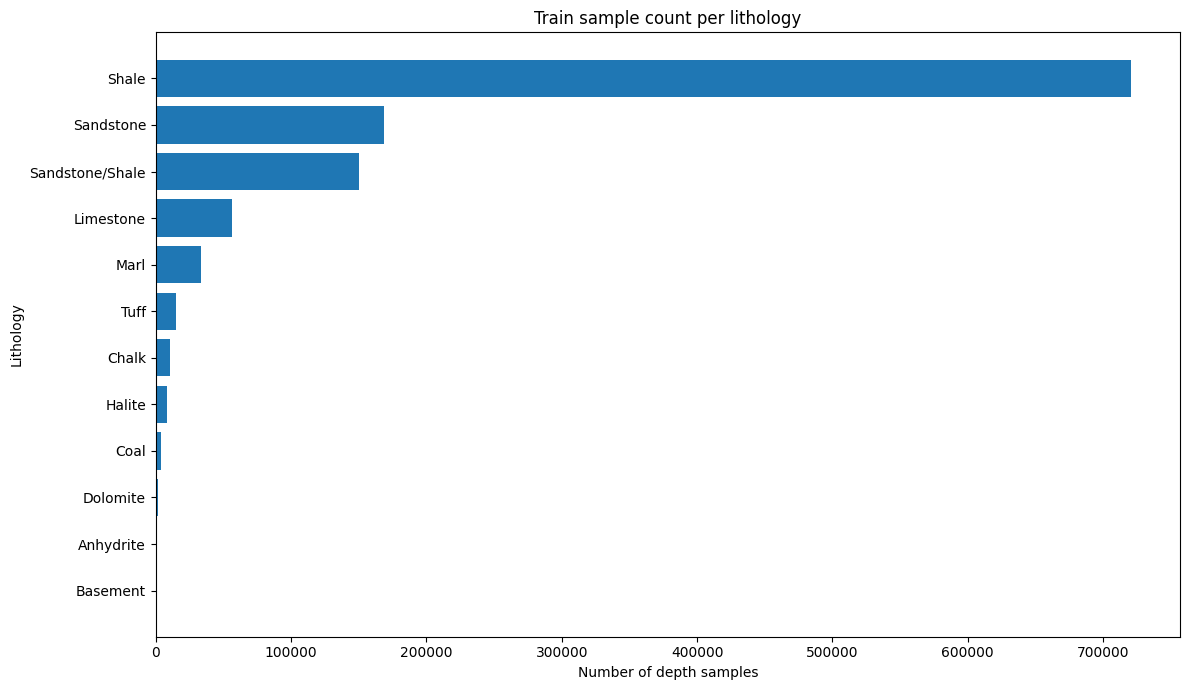

In [24]:

# ============================================================
# CELL 24 — Class sample counts
# ============================================================

plot_df = sample_distribution.sort_values(
    "Number_of_Samples",
    ascending=True,
)

plt.figure(figsize=(12, 7))
plt.barh(
    plot_df["Lithology"],
    plot_df["Number_of_Samples"],
)
plt.xlabel("Number of depth samples")
plt.ylabel("Lithology")
plt.title("Train sample count per lithology")
plt.tight_layout()
plt.show()


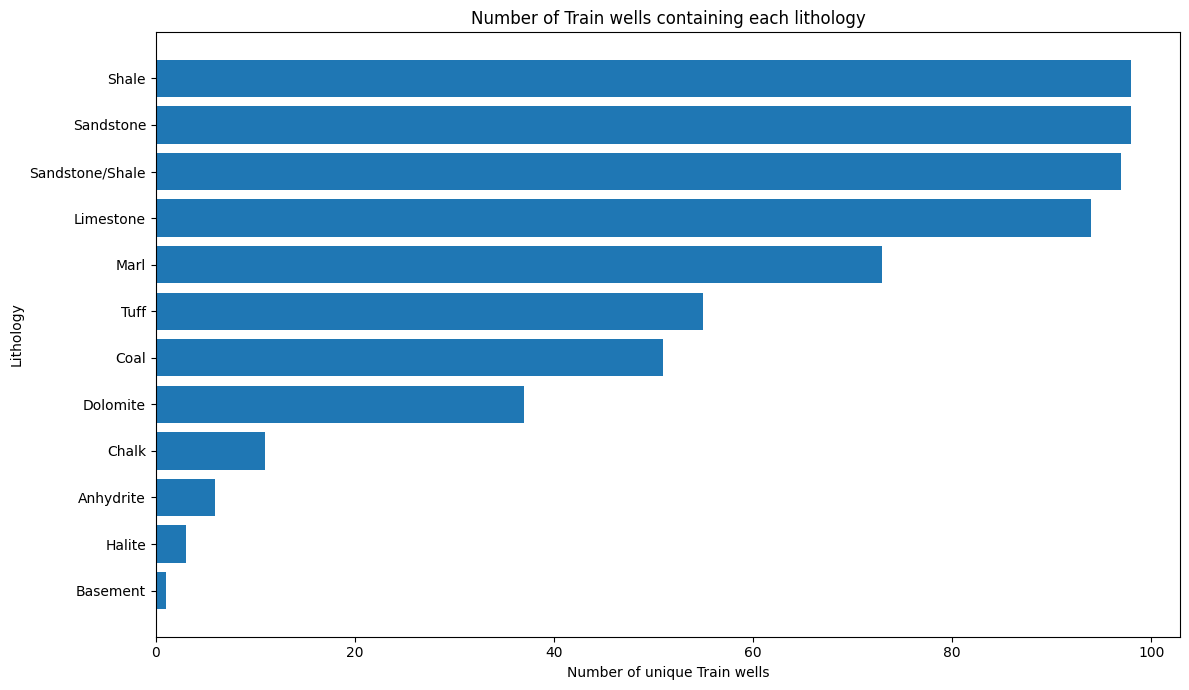

In [25]:

# ============================================================
# CELL 25 — Number of wells containing each class
# ============================================================

plot_df = class_well_summary.sort_values(
    "Number_of_Wells",
    ascending=True,
)

plt.figure(figsize=(12, 7))
plt.barh(
    plot_df["Lithology"],
    plot_df["Number_of_Wells"],
)
plt.xlabel("Number of unique Train wells")
plt.ylabel("Lithology")
plt.title("Number of Train wells containing each lithology")
plt.tight_layout()
plt.show()


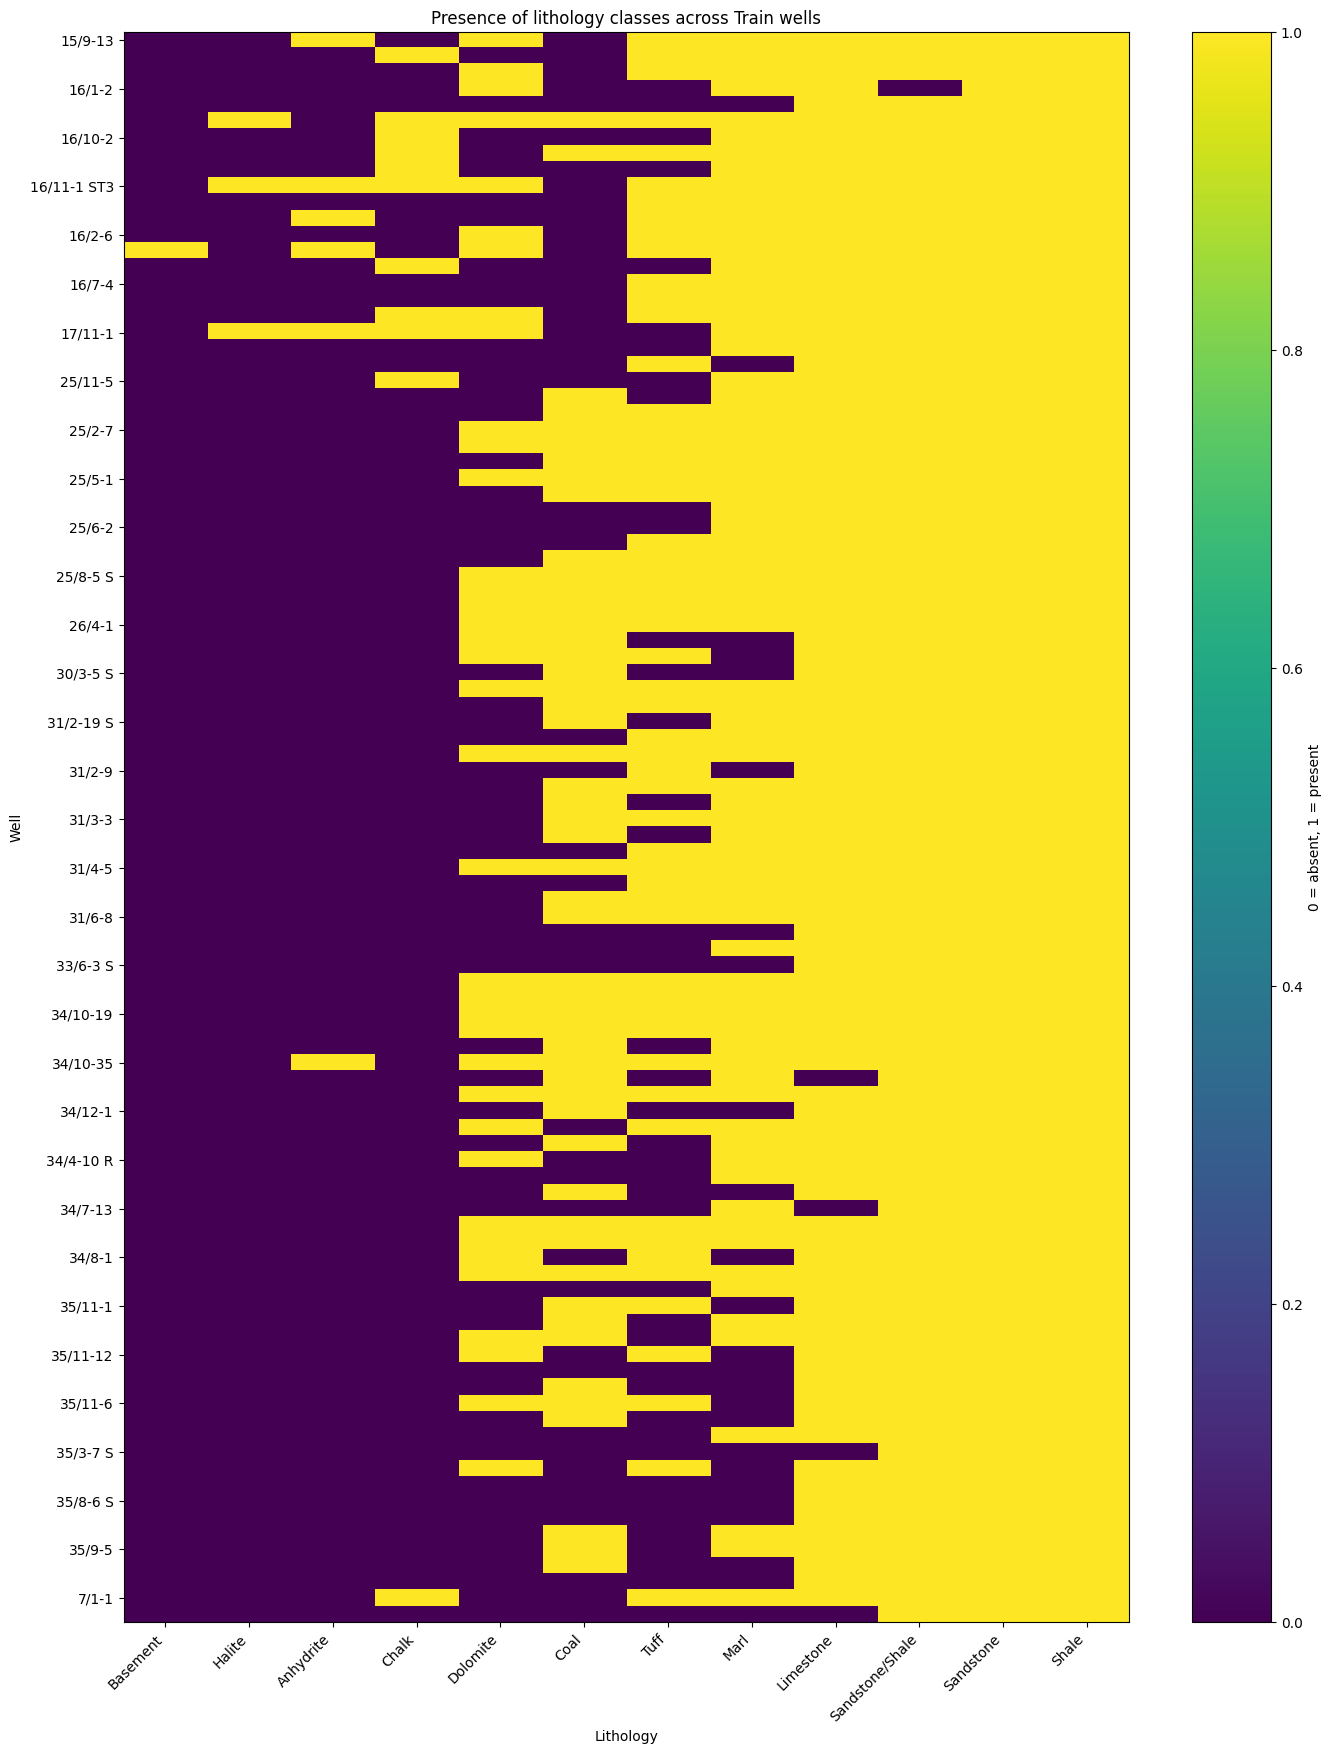

In [ ]:

# ============================================================
# CELL 26 — Presence heatmap: WELL × Lithology
# ============================================================

ordered_classes = (
    well_class_presence_matrix
    .sum(axis=0)
    .sort_values()
    .index
)

heatmap_data = well_class_presence_matrix[ordered_classes].to_numpy()

fig, ax = plt.subplots(
    figsize=(14, max(12, 0.18 * len(well_class_presence_matrix)))
)

image = ax.imshow(
    heatmap_data,
    aspect="auto",
    interpolation="nearest",
)

ax.set_xticks(np.arange(len(ordered_classes)))
ax.set_xticklabels(
    ordered_classes,
    rotation=45,
    ha="right",
)


step = max(1, len(well_class_presence_matrix) // 25)
yticks = np.arange(0, len(well_class_presence_matrix), step)

ax.set_yticks(yticks)
ax.set_yticklabels(
    well_class_presence_matrix.index[yticks]
)

ax.set_xlabel("Lithology")
ax.set_ylabel("Well")
ax.set_title("Presence of lithology classes across Train wells")

fig.colorbar(image, ax=ax, label="0 = absent, 1 = present")
plt.tight_layout()
plt.show()


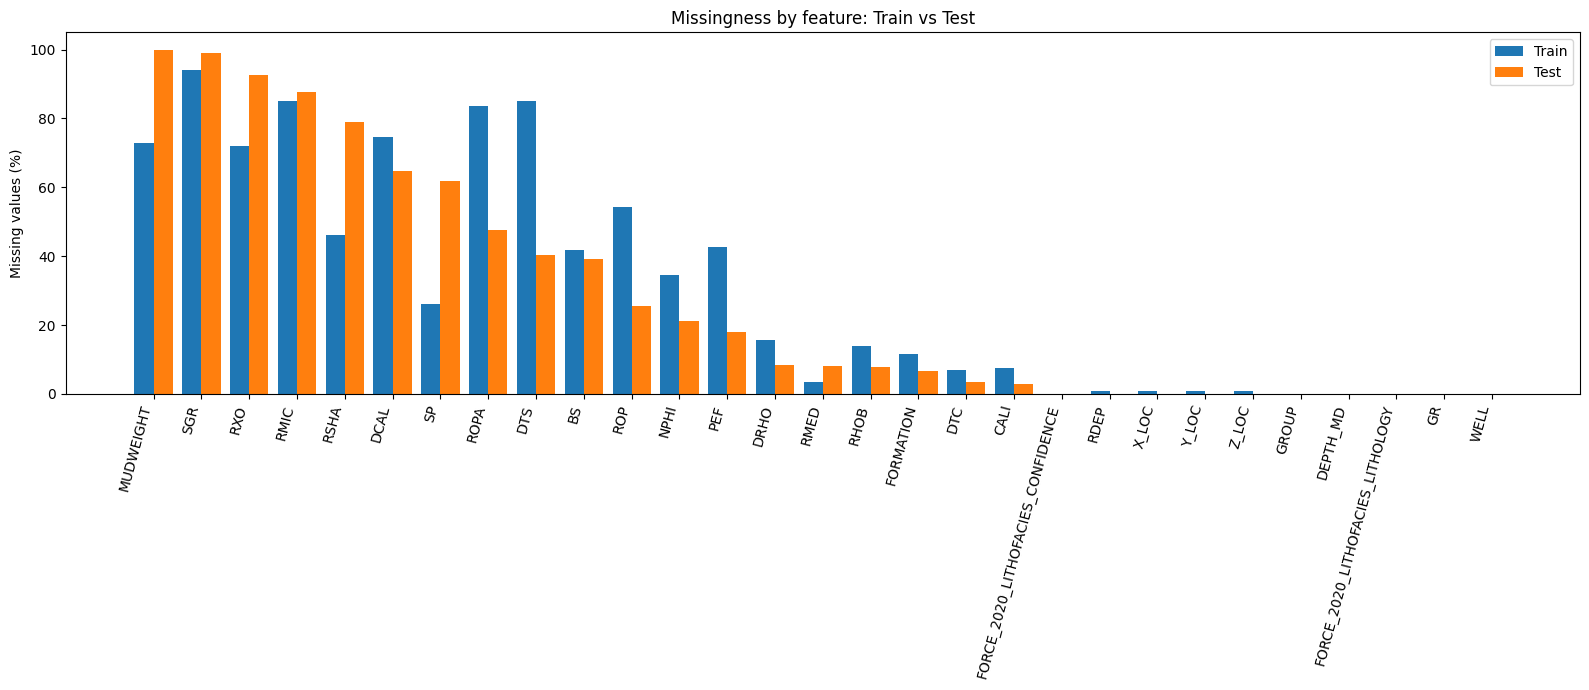

In [27]:

# ============================================================
# CELL 27 — Missingness comparison plot
# ============================================================

missing_plot = (
    pd.concat(
        [
            train_missingness[["Dataset", "Column", "Missing_Percent"]],
            test_missingness[["Dataset", "Column", "Missing_Percent"]],
        ],
        ignore_index=True,
    )
    .pivot(
        index="Column",
        columns="Dataset",
        values="Missing_Percent",
    )
    .fillna(0)
)

missing_plot = missing_plot.sort_values(
    by=list(missing_plot.columns),
    ascending=False,
)

x = np.arange(len(missing_plot))
width = 0.4

fig, ax = plt.subplots(figsize=(16, 7))

if "Train" in missing_plot.columns:
    ax.bar(
        x - width / 2,
        missing_plot["Train"].values,
        width,
        label="Train",
    )

if "Test" in missing_plot.columns:
    ax.bar(
        x + width / 2,
        missing_plot["Test"].values,
        width,
        label="Test",
    )

ax.set_xticks(x)
ax.set_xticklabels(
    missing_plot.index,
    rotation=75,
    ha="right",
)
ax.set_ylabel("Missing values (%)")
ax.set_title("Missingness by feature: Train vs Test")
ax.legend()

plt.tight_layout()
plt.show()


In [28]:

# ============================================================
# CELL 28 — Save audit outputs
# ============================================================

tables_to_save = {
    "dataset_overview.csv": overview,
    "column_audit.csv": column_audit,
    "dtype_mismatches.csv": dtype_mismatches,
    "train_sample_distribution.csv": sample_distribution,
    "train_class_well_summary.csv": class_well_summary,
    "train_wells_per_class.csv": wells_per_class,
    "train_samples_per_class_per_well.csv": train_class_well_counts,
    "train_well_class_count_matrix.csv": well_class_count_matrix.reset_index(),
    "train_well_class_presence_matrix.csv": well_class_presence_matrix.reset_index(),
    "train_class_well_thresholds.csv": class_well_thresholds,
    "train_class_concentration.csv": class_concentration,
    "train_missingness.csv": train_missingness,
    "test_missingness.csv": test_missingness,
    "train_quality_flags.csv": train_quality_flags,
    "test_quality_flags.csv": test_quality_flags,
    "train_numeric_summary.csv": train_numeric_summary,
    "test_numeric_summary.csv": test_numeric_summary,
    "train_depth_audit.csv": train_depth_audit,
    "test_depth_audit.csv": test_depth_audit,
    "duplicate_summary.csv": duplicate_summary,
    "train_test_numeric_range_comparison.csv": train_test_range_comparison,
}

if not test_sample_distribution.empty:
    tables_to_save["test_sample_distribution.csv"] = (
        test_sample_distribution
    )

if not test_class_well_summary.empty:
    tables_to_save["test_class_well_summary.csv"] = (
        test_class_well_summary
    )

for filename, table in tables_to_save.items():
    table.to_csv(
        OUTPUT_DIR / filename,
        index=False,
    )

print(f"✅ Saved {len(tables_to_save)} audit tables to:")
print(OUTPUT_DIR)


✅ Saved 23 audit tables to:
/Users/mohaddesemoghaddam/Desktop/force2020_dataset_audit
